In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

TRAIN_PATH = "/content/sample_data/train.csv"
TEST_PATH = "/content/sample_data/test_features.csv"

TARGET = "prediction"

OTHER_TARGETS = [
    "Статус_глюкозы",
    "Доклинический_риск",
]

ID_COLUMN = "patient_id"

In [2]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Train:", train.shape)
print("Test :", test.shape)

display(train.head())
display(test.head())

Train: (800, 19)
Test : (200, 18)


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,Статус_глюкозы,Доклинический_риск
0,2,46,0,22.88,80.54,117.32,62.11,55.21,4.964,4.00,2.443,1.269,1.903,97.72,0,195.0,0,0
1,3,64,0,21.99,78.42,121.25,71.46,49.79,4.713,5.03,4.213,NaN,NaN,81.54,0,193.2,0,0
2,8,45,1,18.40,82.16,91.84,70.57,21.27,5.417,4.87,2.590,1.509,2.068,89.60,0,278.3,0,0
3,18,55,0,22.79,86.58,111.82,70.98,40.84,4.516,4.35,2.194,1.756,0.650,93.33,0,207.3,0,0
4,19,60,0,23.87,86.99,119.58,64.13,55.45,4.871,4.79,4.139,1.296,0.961,83.51,0,194.0,0,0


In [3]:
print("TRAIN INFO")
print("=" * 50)

print(train.info())

print("\nПропуски:")
display(
    train.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing")
)

print("\nРаспределение prediction:")
display(train[TARGET].value_counts())

print("\nДоли классов:")
display(train[TARGET].value_counts(normalize=True))

TRAIN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     800 non-null    int64  
 1   Возраст                        800 non-null    int64  
 2   Пол_мужской                    800 non-null    int64  
 3   ИМТ                            800 non-null    float64
 4   Окружность_талии_см            800 non-null    float64
 5   САД_мм_рт_ст                   800 non-null    float64
 6   ДАД_мм_рт_ст                   800 non-null    float64
 7   Пульсовое_давление             800 non-null    float64
 8   Глюкоза_натощак_ммоль_л        800 non-null    float64
 9   HbA1c_%                        800 non-null    float64
 10  ЛПНП_ммоль_л                   765 non-null    float64
 11  ЛПВП_ммоль_л                   755 non-null    float64
 12  Триглицериды_ммоль_л           754 non-

,missing
СКФ_мл_мин,47
Триглицериды_ммоль_л,46
ЛПВП_ммоль_л,45
ЛПНП_ммоль_л,35
Пол_мужской,0
patient_id,0
Возраст,0
ДАД_мм_рт_ст,0
ИМТ,0
САД_мм_рт_ст,0



Распределение prediction:


,count
prediction,
0,655
1,145



Доли классов:


,proportion
prediction,
0,0.81875
1,0.18125


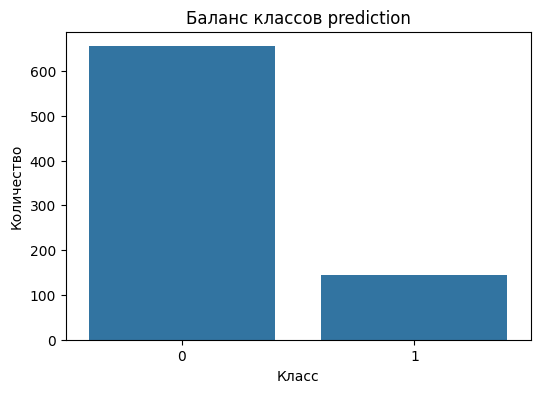

In [4]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=train,
    x=TARGET,
)

plt.title("Баланс классов prediction")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.show()

In [5]:
FEATURE_COLUMNS = [
    column
    for column in train.columns
    if column not in [
        ID_COLUMN,
        TARGET,
        *OTHER_TARGETS,
    ]
]

print("Количество признаков:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)

Количество признаков: 15
['Возраст', 'Пол_мужской', 'ИМТ', 'Окружность_талии_см', 'САД_мм_рт_ст', 'ДАД_мм_рт_ст', 'Пульсовое_давление', 'Глюкоза_натощак_ммоль_л', 'HbA1c_%', 'ЛПНП_ммоль_л', 'ЛПВП_ммоль_л', 'Триглицериды_ммоль_л', 'СКФ_мл_мин', 'Курение', 'Физическая_активность_мин_нед']


In [6]:
X = train[FEATURE_COLUMNS].apply(
    pd.to_numeric,
    errors="coerce",
)

y = train[TARGET].astype(int)

X_test = test[FEATURE_COLUMNS].apply(
    pd.to_numeric,
    errors="coerce",
)

print("X:", X.shape)
print("X_test:", X_test.shape)

display(X.head())

X: (800, 15)
X_test: (200, 15)


,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед
0,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8
1,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1
2,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5
3,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5
4,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4


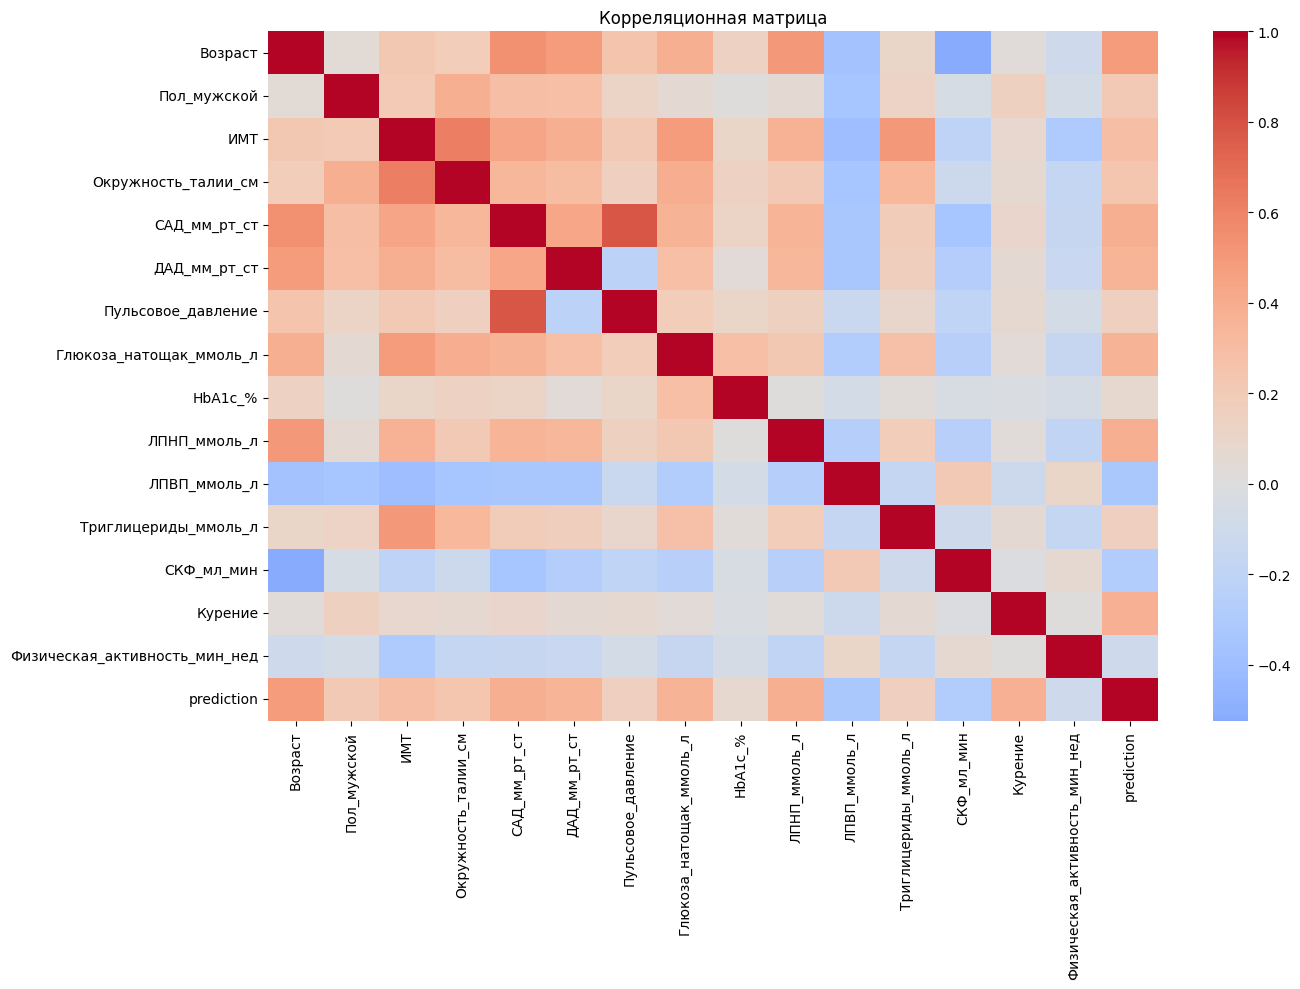

In [7]:
plt.figure(figsize=(14, 10))

correlation = X.copy()
correlation[TARGET] = y

sns.heatmap(
    correlation.corr(),
    cmap="coolwarm",
    center=0,
)

plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

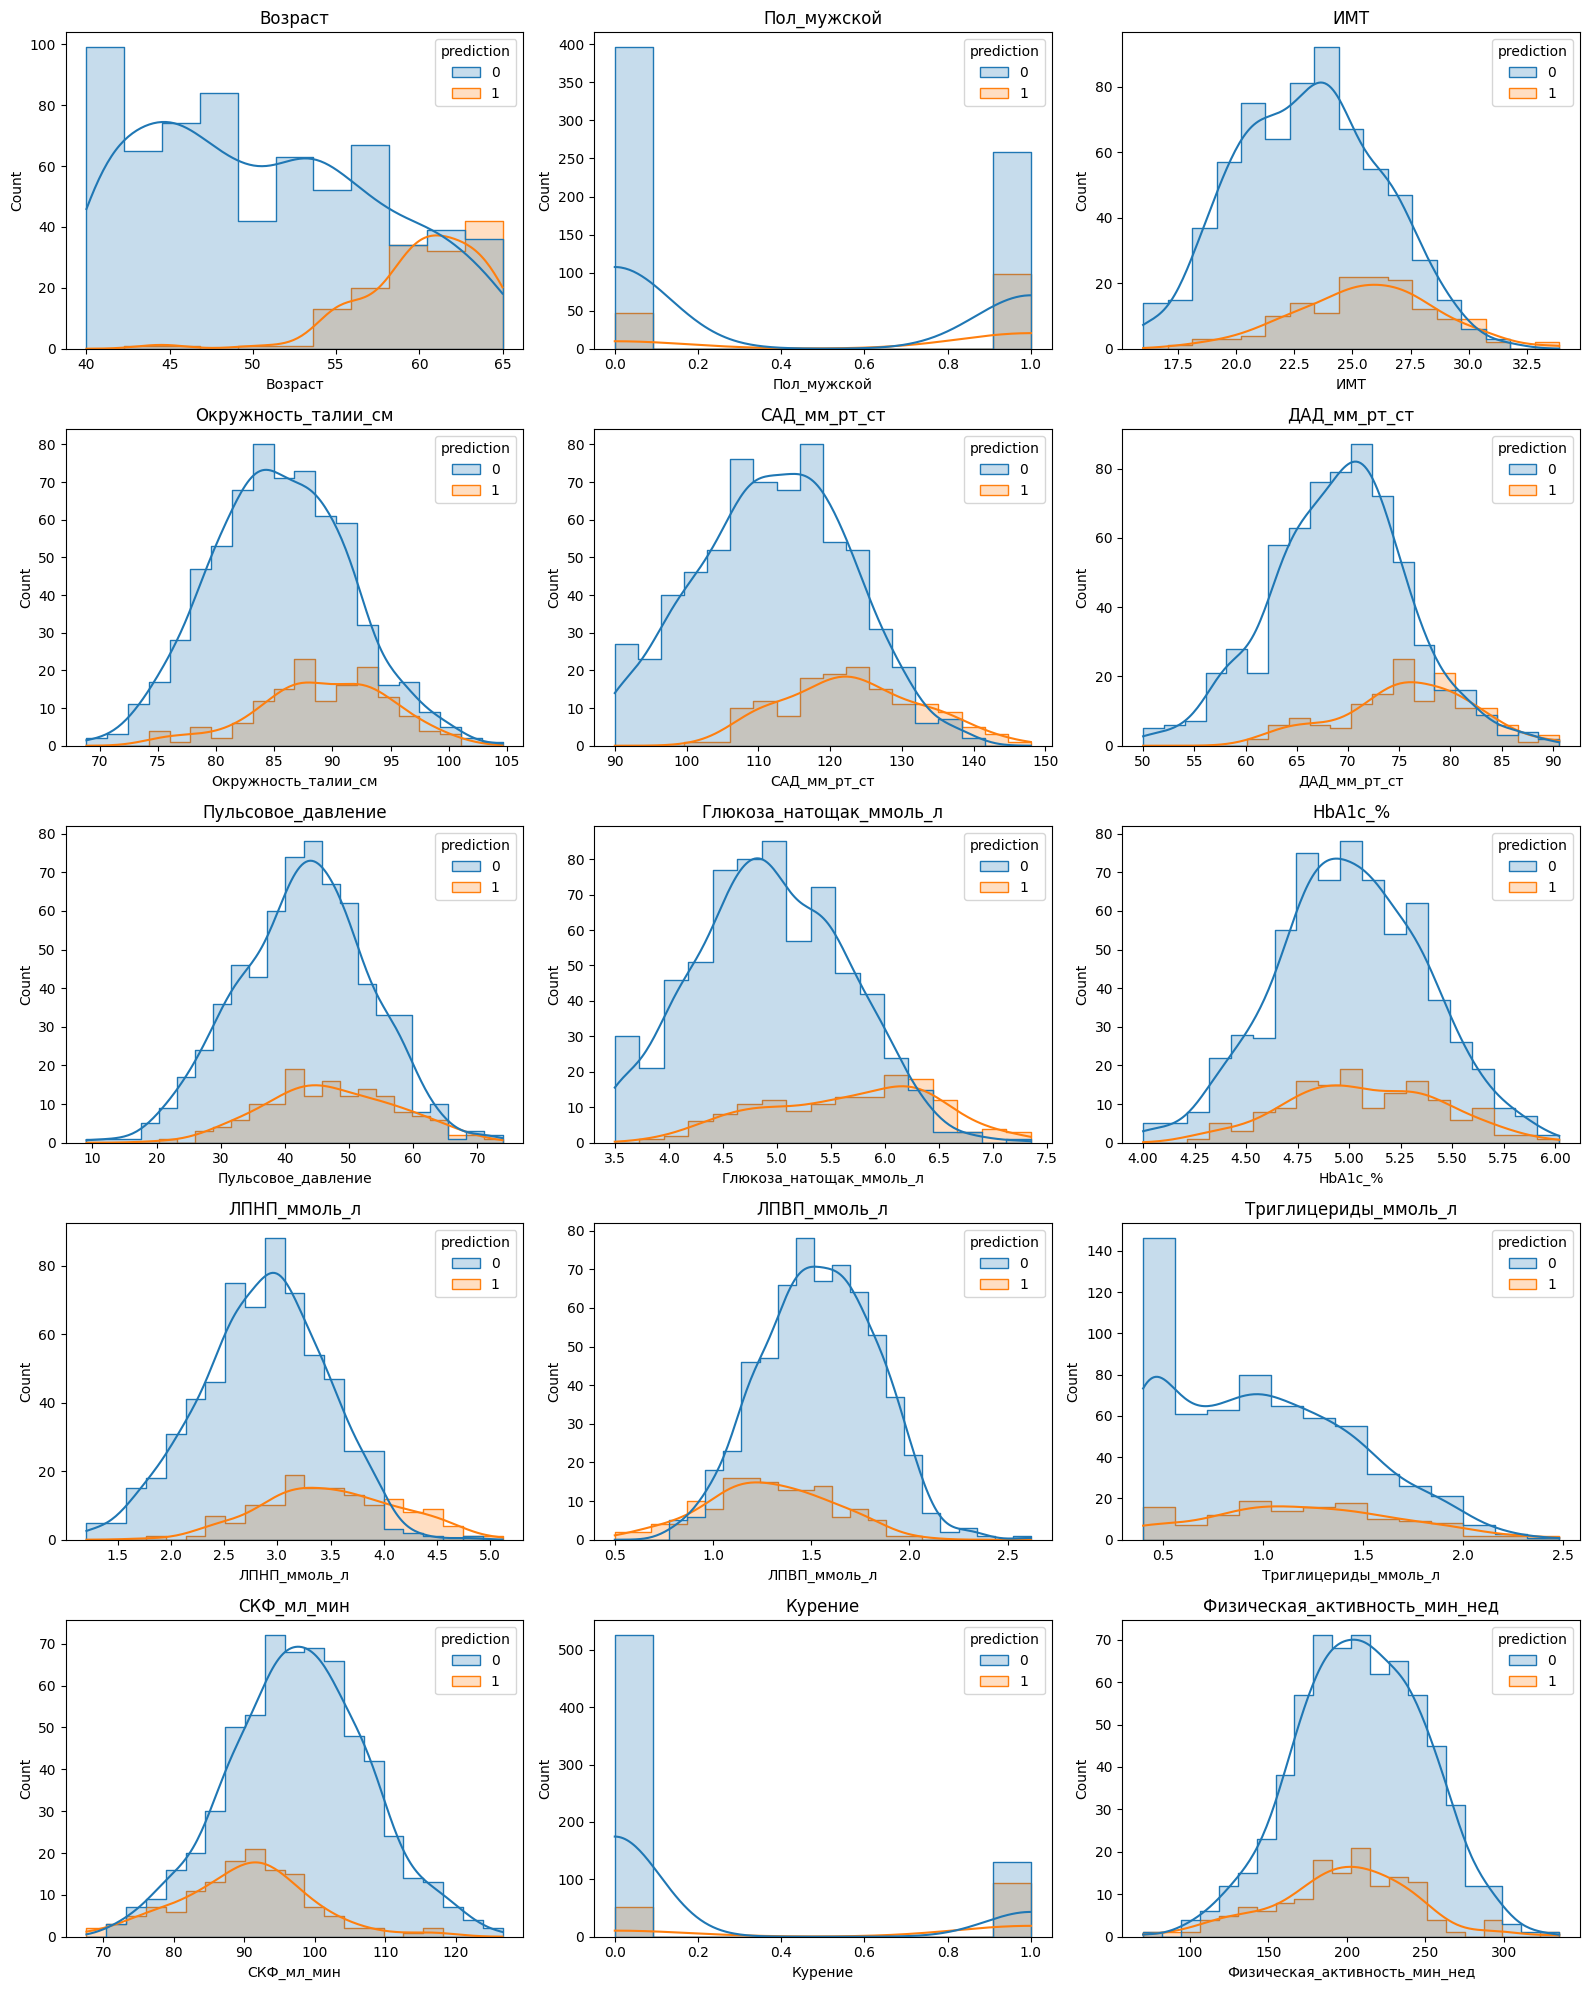

In [8]:
numeric_columns = X.columns.tolist()

n_cols = 3
n_rows = int(np.ceil(len(numeric_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4),
)

axes = np.array(axes).reshape(-1)

for ax, column in zip(axes, numeric_columns):
    sns.histplot(
        data=train,
        x=column,
        hue=TARGET,
        kde=True,
        ax=ax,
        element="step",
    )

    ax.set_title(column)

for ax in axes[len(numeric_columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

print("\nTrain classes:")
print(y_train.value_counts())

print("\nValidation classes:")
print(y_val.value_counts())

Train: (640, 15)
Validation: (160, 15)

Train classes:
prediction
0    524
1    116
Name: count, dtype: int64

Validation classes:
prediction
0    131
1     29
Name: count, dtype: int64


In [10]:
model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "classifier",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])

In [11]:
y_pred = model.predict(X_val)

y_proba = model.predict_proba(X_val)[:, 1]

In [12]:
cm = confusion_matrix(
    y_val,
    y_pred,
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

metrics = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "Specificity": specificity,
    "Precision": precision_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "ROC-AUC": roc_auc_score(y_val, y_proba),
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"],
)

display(metrics_df)

,Metric,Value
0,Accuracy,0.943750
1,Recall,1.000000
2,Specificity,0.931298
3,Precision,0.763158
4,F1,0.865672
5,ROC-AUC,0.991050


In [13]:
print(
    classification_report(
        y_val,
        y_pred,
        digits=4,
    )
)

              precision    recall  f1-score   support

           0     1.0000    0.9313    0.9644       131
           1     0.7632    1.0000    0.8657        29

    accuracy                         0.9437       160
   macro avg     0.8816    0.9656    0.9150       160
weighted avg     0.9571    0.9437    0.9465       160



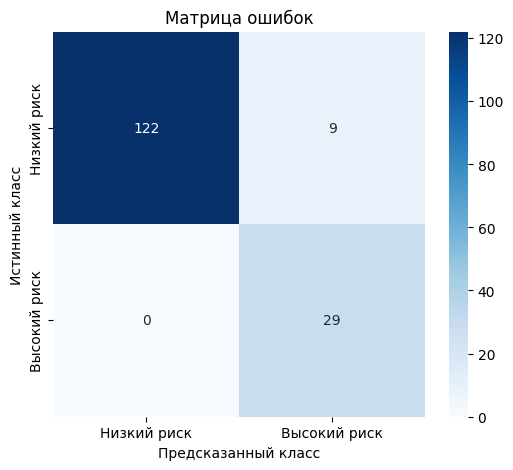

In [14]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Низкий риск", "Высокий риск"],
    yticklabels=["Низкий риск", "Высокий риск"],
)

plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок")
plt.show()

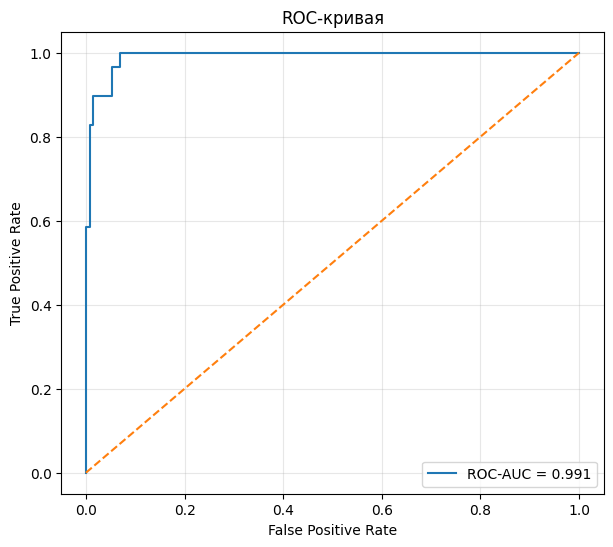

In [15]:
fpr, tpr, thresholds = roc_curve(
    y_val,
    y_proba,
)

auc = roc_auc_score(
    y_val,
    y_proba,
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.3f}",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
)

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE,
)

X_pca = pca.fit_transform(
    X_train_scaled
)

print(
    "Объяснённая дисперсия:",
    pca.explained_variance_ratio_,
)

print(
    "Суммарно:",
    pca.explained_variance_ratio_.sum(),
)

Объяснённая дисперсия: [0.28834571 0.1039526 ]
Суммарно: 0.39229831001210536


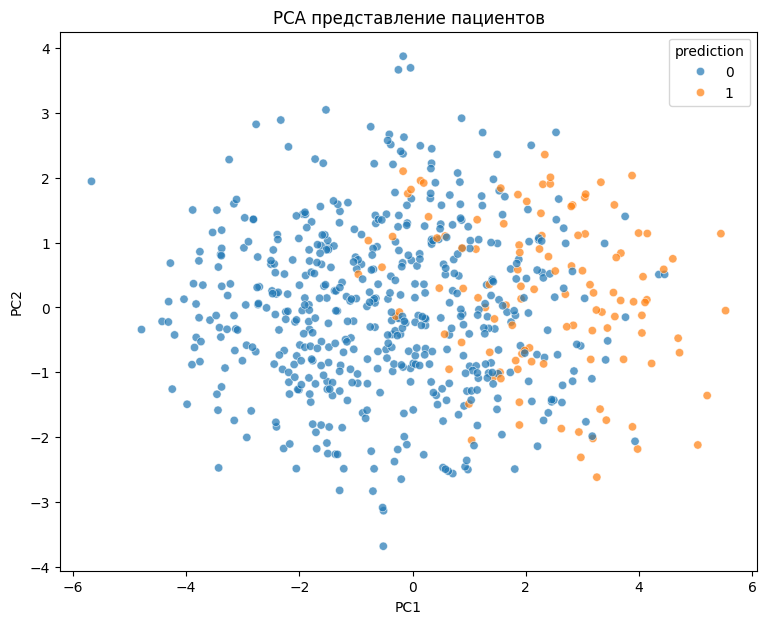

In [17]:
pca_df = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "prediction": y_train.values,
    }
)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="prediction",
    alpha=0.7,
)

plt.title("PCA представление пациентов")
plt.show()

In [18]:
GLUCOSE_COLUMN = "Глюкоза_натощак_ммоль_л"

border_mask = (
    X_val[GLUCOSE_COLUMN].between(
        5.4,
        6.5,
        inclusive="both",
    )
)

X_border = X_val.loc[border_mask]
y_border = y_val.loc[border_mask]

print(
    "Пограничных пациентов:",
    len(X_border),
)

Пограничных пациентов: 47


In [19]:
fuzzy_imputer = SimpleImputer(
    strategy="median",
)

X_train_fuzzy = fuzzy_imputer.fit_transform(
    X_train
)

X_border_fuzzy = fuzzy_imputer.transform(
    X_border
)

fuzzy_scaler = StandardScaler()

X_train_fuzzy = fuzzy_scaler.fit_transform(
    X_train_fuzzy
)

X_border_fuzzy = fuzzy_scaler.transform(
    X_border_fuzzy
)

In [20]:
K = 15

neighbors_model = NearestNeighbors(
    n_neighbors=K,
    metric="euclidean",
)

neighbors_model.fit(X_train_fuzzy)

distances, indices = neighbors_model.kneighbors(
    X_border_fuzzy
)

In [21]:
def fuzzy_knn_predict(
    distances,
    indices,
    y_train,
    power=2.0,
):
    results = []

    for patient_distances, patient_indices in zip(
        distances,
        indices,
    ):
        weights = 1 / (
            patient_distances + 1e-8
        ) ** power

        neighbor_classes = y_train.iloc[
            patient_indices
        ].to_numpy()

        class_0_weight = weights[
            neighbor_classes == 0
        ].sum()

        class_1_weight = weights[
            neighbor_classes == 1
        ].sum()

        total_weight = (
            class_0_weight
            + class_1_weight
        )

        membership_0 = (
            class_0_weight / total_weight
        )

        membership_1 = (
            class_1_weight / total_weight
        )

        risk_score = membership_1

        uncertainty = (
            1
            - abs(
                membership_1
                - membership_0
            )
        )

        predicted_class = int(
            membership_1 >= 0.5
        )

        results.append(
            {
                "membership_0": membership_0,
                "membership_1": membership_1,
                "risk_score": risk_score,
                "uncertainty": uncertainty,
                "prediction": predicted_class,
            }
        )

    return pd.DataFrame(results)

In [22]:
fuzzy_results = fuzzy_knn_predict(
    distances,
    indices,
    y_train,
)

fuzzy_results.index = X_border.index

fuzzy_results[
    GLUCOSE_COLUMN
] = X_border[GLUCOSE_COLUMN]

fuzzy_results[
    "true_class"
] = y_border

display(
    fuzzy_results.sort_values(
        "uncertainty",
        ascending=False,
    ).head(20)
)

,membership_0,membership_1,risk_score,uncertainty,prediction,Глюкоза_натощак_ммоль_л,true_class
127,0.496952,0.503048,0.503048,0.993903,1,5.607,1
596,0.523488,0.476512,0.476512,0.953024,0,5.409,0
446,0.476121,0.523879,0.523879,0.952243,1,5.573,1
683,0.534354,0.465646,0.465646,0.931292,0,6.368,1
606,0.565996,0.434004,0.434004,0.868008,0,5.525,1
134,0.392967,0.607033,0.607033,0.785933,1,6.375,1
686,0.623000,0.377000,0.377000,0.754000,0,5.928,0
548,0.287728,0.712272,0.712272,0.575455,1,5.843,1
164,0.744845,0.255155,0.255155,0.510310,0,5.764,0
91,0.750322,0.249678,0.249678,0.499355,0,6.113,1


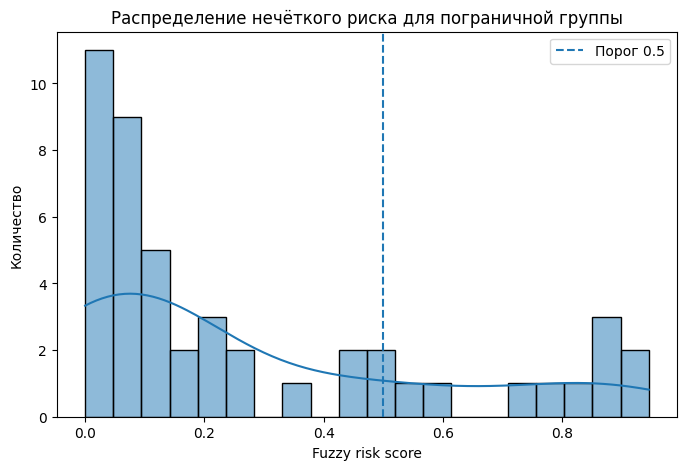

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    fuzzy_results["risk_score"],
    bins=20,
    kde=True,
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Порог 0.5",
)

plt.xlabel("Fuzzy risk score")
plt.ylabel("Количество")
plt.title(
    "Распределение нечёткого риска "
    "для пограничной группы"
)

plt.legend()
plt.show()

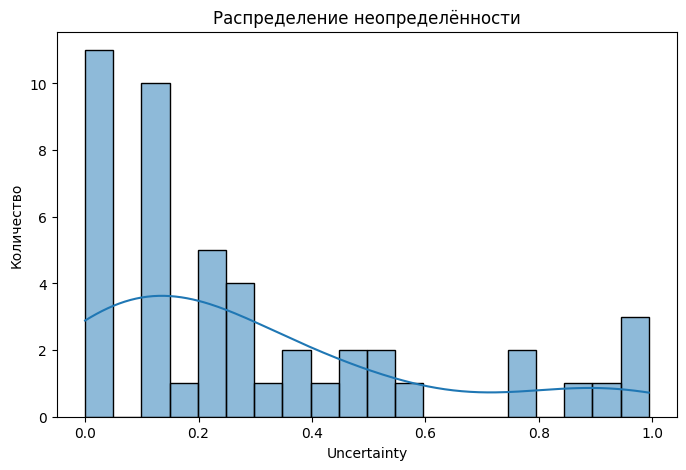

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    fuzzy_results["uncertainty"],
    bins=20,
    kde=True,
)

plt.xlabel("Uncertainty")
plt.ylabel("Количество")
plt.title("Распределение неопределённости")
plt.show()

In [25]:
most_uncertain = (
    fuzzy_results
    .sort_values(
        "uncertainty",
        ascending=False,
    )
    .head(10)
)

display(most_uncertain)

,membership_0,membership_1,risk_score,uncertainty,prediction,Глюкоза_натощак_ммоль_л,true_class
127,0.496952,0.503048,0.503048,0.993903,1,5.607,1
596,0.523488,0.476512,0.476512,0.953024,0,5.409,0
446,0.476121,0.523879,0.523879,0.952243,1,5.573,1
683,0.534354,0.465646,0.465646,0.931292,0,6.368,1
606,0.565996,0.434004,0.434004,0.868008,0,5.525,1
134,0.392967,0.607033,0.607033,0.785933,1,6.375,1
686,0.623000,0.377000,0.377000,0.754000,0,5.928,0
548,0.287728,0.712272,0.712272,0.575455,1,5.843,1
164,0.744845,0.255155,0.255155,0.510310,0,5.764,0
91,0.750322,0.249678,0.249678,0.499355,0,6.113,1


In [26]:
examples = (
    fuzzy_results
    .sort_values("uncertainty", ascending=False)
    .head(10)
    [
        [
            GLUCOSE_COLUMN,
            "membership_0",
            "membership_1",
            "risk_score",
            "uncertainty",
            "prediction",
        ]
    ]
)

display(examples)

,Глюкоза_натощак_ммоль_л,membership_0,membership_1,risk_score,uncertainty,prediction
127,5.607,0.496952,0.503048,0.503048,0.993903,1
596,5.409,0.523488,0.476512,0.476512,0.953024,0
446,5.573,0.476121,0.523879,0.523879,0.952243,1
683,6.368,0.534354,0.465646,0.465646,0.931292,0
606,5.525,0.565996,0.434004,0.434004,0.868008,0
134,6.375,0.392967,0.607033,0.607033,0.785933,1
686,5.928,0.623000,0.377000,0.377000,0.754000,0
548,5.843,0.287728,0.712272,0.712272,0.575455,1
164,5.764,0.744845,0.255155,0.255155,0.510310,0
91,6.113,0.750322,0.249678,0.249678,0.499355,0


In [27]:
final_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "classifier",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                probability=True,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

final_model.fit(
    X,
    y,
)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 SVC(class_weight='balanced', probability=True,
                     random_state=42))])

In [28]:
test_predictions = final_model.predict(
    X_test
)

print(
    "Количество предсказаний:",
    len(test_predictions),
)

print(
    "Количество строк test:",
    len(test),
)

Количество предсказаний: 200
Количество строк test: 200


In [29]:
output = pd.DataFrame(
    {
        "patient_id": test[ID_COLUMN],
        "prediction": test_predictions,
    }
)

assert len(output) == len(test)
assert output["patient_id"].equals(
    test[ID_COLUMN]
)

assert output["patient_id"].notna().all()
assert output["prediction"].notna().all()

os.makedirs(
    "outputs",
    exist_ok=True,
)

OUTPUT_PATH = "/content/sample_data/task1_predictions.csv"

output.to_csv(
    OUTPUT_PATH,
    index=False,
)

print(f"Файл сохранён: {OUTPUT_PATH}")

display(output.head(10))

Файл сохранён: /content/sample_data/task1_predictions.csv


,patient_id,prediction
0,2,0
1,3,1
2,8,0
3,18,0
4,19,0
5,20,0
6,28,0
7,29,0
8,37,0
9,43,0


In [30]:
check = pd.read_csv(
    OUTPUT_PATH
)

print(check.shape)
print(check.columns.tolist())

display(check.head())

assert list(check.columns) == [
    "patient_id",
    "prediction",
]

assert len(check) == len(test)

assert check["patient_id"].notna().all()
assert check["prediction"].notna().all()

print("✓ Контракт отправки выполнен")

(200, 2)
['patient_id', 'prediction']


,patient_id,prediction
0,2,0
1,3,1
2,8,0
3,18,0
4,19,0


✓ Контракт отправки выполнен


## Отчёт по заданию 1

Для классификации высокого сердечно-сосудистого риска была разработана модель SVM с RBF-ядром. Данные разделены на обучающую и валидационную выборки в соотношении 80:20 с сохранением баланса классов. Из признаков исключены `patient_id` и все целевые переменные, что предотвращает утечку целевой информации. Пропуски числовых признаков заполнены медианами, а данные стандартизированы. Предобработка выполнялась внутри Pipeline и обучалась только на обучающей выборке. Для компенсации дисбаланса классов использовался параметр `class_weight="balanced"`.

Качество модели на валидационной выборке составило: Accuracy = 94,38%, Recall = 100%, Specificity = 93,13%, Precision = 76,32%, F1 = 86,57%, ROC-AUC = 99,11%. Модель обнаружила все положительные случаи в валидационной выборке, однако часть пациентов класса 0 была ошибочно отнесена к классу 1. Корреляционный анализ и PCA использовались для исследования структуры данных и взаимосвязей признаков.

Для пациентов с уровнем глюкозы натощак 5,4–6,5 ммоль/л реализован нечёткий KNN. На основе расстояний до ближайших соседей рассчитаны степени принадлежности к классам, оценка риска и неопределённость прогнозов.

После оценки качества модель обучена на полном обучающем наборе и использована для формирования прогнозов тестовой выборки. Результаты сохранены в `/content/sample_data/task1_predictions.csv` с идентификаторами пациентов и предсказанными классами.

Данные являются симулированными, поэтому результаты не подтверждают клиническую применимость модели. Высокий ROC-AUC требует дополнительной проверки на утечку данных и устойчивость качества. Выбор порога классификации влияет на соотношение ложноотрицательных и ложноположительных прогнозов. Модель предназначена для учебных целей и не заменяет клиническое решение.
